# ĐỀ TÀI 3 - PHÂN TÍCH SẢN PHẨM VÀ THỊ TRƯỜNG TẠO DOANH THU CAO

**Mục tiêu:** Xác định các sản phẩm và quốc gia đóng góp Doanh thu lớn trong bộ dữ liệu **Online Retail**, so sánh Doanh thu với Số lượng bán và khảo sát mối liên hệ giữa các biến giao dịch.

**Câu hỏi nghiên cứu:**
1. Sản phẩm nào tạo Doanh thu cao nhất và sản phẩm nào được bán nhiều nhất ?
2. Doanh thu tập trung ở những Quốc gia nào ?
3. Quantity, UnitPrice và Revenue có mối liên hệ như thế nào ?

Doanh thu giao dịch được tính bằng `Quantity × UnitPrice`, phản ánh tổng giá trị bán hàng của các dòng giao dịch được giữ lại sau quá trình tiền xử lý. Các kết quả phân tích phụ thuộc vào quy tắc làm sạch dữ liệu và cần được diễn giải trong phạm vi nghiên cứu.

**PHẦN 1. KHỞI TẠO VÀ ĐỌC DỮ LIỆU**
- Import thư viện cần thiết cho xử lý và phân tích dữ liệu.
- Chuẩn bị môi trường làm việc trên Google Colab.

In [1]:
# Khởi tạo thư viện và đọc dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Đã khởi tạo thư viện thành công!")

Đã khởi tạo thư viện thành công!


**PHẦN 2. MÔ TẢ DỮ LIỆU**
- Đọc dữ liệu bán lẻ từ file **Online Retail.xlsx**.
- Kiểm tra kích thước và các dòng dữ liệu mẫu.
- Khảo sát tên biến, kiểu dữ liệu, giá trị thiếu và bản ghi trùng lặp.
- Đánh giá sơ bộ chất lượng dữ liệu trước khi xử lý.

In [2]:
# Đọc file Excel Online Retail
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df_raw = pd.read_excel(file_name)
print("Đã đọc dữ liệu thành công!")

Saving Online Retail.xlsx to Online Retail.xlsx
Đã đọc dữ liệu thành công!


In [3]:
# Kiểm tra kích thước và các dòng dữ liệu
print(f"Số dòng: {df_raw.shape[0]:,}")
print(f"Số cột: {df_raw.shape[1]:,}")
display(df_raw.head())

Số dòng: 541,909
Số cột: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Kiểm tra kiểu dữ liệu, giá trị thiếu và trùng lặp
import pandas as pd
summary = pd.DataFrame({
    'Kiểu dữ liệu': df_raw.dtypes.astype(str),
    'Giá trị thiếu': df_raw.isnull().sum(),
    'Tỷ lệ thiếu (%)': (df_raw.isnull().mean() * 100).round(2),
    'Giá trị duy nhất': df_raw.nunique()
})
display(summary)
print(f"Số dòng dữ liệu: {len(df_raw):,}")
print(f"Số cột dữ liệu: {df_raw.shape[1]}")
print(f"Số dòng trùng hoàn toàn: {df_raw.duplicated().sum():,}")

,Kiểu dữ liệu,Giá trị thiếu,Tỷ lệ thiếu (%),Giá trị duy nhất
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,object,0,0.00,38


Số dòng dữ liệu: 541,909
Số cột dữ liệu: 8
Số dòng trùng hoàn toàn: 5,268


**PHẦN 3. TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU**

**Các bước bao gồm:**
- Chuẩn hóa kiểu dữ liệu và loại bản ghi trùng hoàn toàn.
- Nhận diện hóa đơn hủy và xác định các dòng không phù hợp để tính Doanh thu bán hàng dương. Dòng có `Description` thiếu vẫn được giữ nếu các trường thiết yếu hợp lệ, mô tả được thay bằng nhãn để không làm mất giao dịch.
- Áp dụng phương pháp IQR (Interquartile Range) để nhận diện các giá trị ngoại lệ trong biến UnitPrice.

**Phạm vi dữ liệu:** Các giao dịch hủy, số lượng âm và đơn giá không dương không được tính vào phân tích Doanh thu bán hàng chính. Đây là lựa chọn phạm vi phân tích, không có nghĩa những dòng này vô giá trị cho các nghiên cứu khác.

**Xử lý ngoại lệ:** Kết quả IQR được sử dụng để nhận diện các giao dịch có đơn giá khác biệt đáng kể so với phần lớn dữ liệu. Ngoại lệ thống kê không đồng nghĩa với dữ liệu sai hoặc không hợp lệ, vì vậy các bản ghi này được giữ lại nếu không có căn cứ xác định chúng là dữ liệu lỗi. Việc xử lý ngoại lệ được cân nhắc dựa trên mục tiêu phân tích và tính hợp lệ của giao dịch.

In [6]:
# Chuẩn hóa kiểu dữ liệu và loại bản ghi trùng hoàn toàn
rows_original = len(df_raw)
df = df_raw.copy()

for col in ["InvoiceNo", "StockCode", "Country", "Description"]:
    df[col] = df[col].astype("string").str.strip()

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

print(f"Số dòng ban đầu: {rows_original:,}")
print(f"Số bản ghi trùng hoàn toàn đã loại: {duplicate_count:,}")
print(f"Số dòng sau khi loại trùng: {len(df):,}")

Số dòng ban đầu: 541,909
Số bản ghi trùng hoàn toàn đã loại: 5,268
Số dòng sau khi loại trùng: 536,641


In [7]:
# Phân loại và lọc các dòng dùng cho phân tích Doanh thu bán hàng
cancel_mask = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
missing_essential_mask = df[
    ["InvoiceNo", "StockCode", "Country", "InvoiceDate", "Quantity", "UnitPrice"]
].isna().any(axis=1)
nonpositive_quantity_mask = df["Quantity"].le(0)
nonpositive_price_mask = df["UnitPrice"].le(0)

valid_mask = (
    (~cancel_mask)
    & (~missing_essential_mask)
    & (~nonpositive_quantity_mask)
    & (~nonpositive_price_mask)
)

df_clean = df.loc[valid_mask].copy()
df_clean["Description"] = df_clean["Description"].fillna("Không có mô tả")
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

cleaning_summary = pd.DataFrame({
    "Chỉ tiêu": [
        "Số dòng ban đầu",
        "Bản ghi trùng hoàn toàn đã loại",
        "Số dòng sau loại trùng",
        "Dòng hóa đơn hủy (trong dữ liệu sau loại trùng)",
        "Dòng thiếu trường thiết yếu",
        "Dòng có Quantity <= 0",
        "Dòng có UnitPrice <= 0",
        "Số dòng được giữ lại để phân tích",
        "Số dòng bị loại sau bước lọc"
    ],
    "Giá trị": [
        rows_original, duplicate_count, len(df), int(cancel_mask.sum()),
        int(missing_essential_mask.sum()), int(nonpositive_quantity_mask.sum()),
        int(nonpositive_price_mask.sum()), len(df_clean), len(df) - len(df_clean)
    ]
})
display(cleaning_summary)
print(
    "\nGhi chú phương pháp: Các tiêu chí loại trừ không loại trừ lẫn nhau, "
    "một bản ghi có thể đồng thời thuộc nhiều nhóm. "
    "Do đó, số lượng của từng nhóm không được cộng trực tiếp "
    "để xác định tổng số bản ghi bị loại."
)

,Chỉ tiêu,Giá trị
0,Số dòng ban đầu,541909
1,Bản ghi trùng hoàn toàn đã loại,5268
2,Số dòng sau loại trùng,536641
3,Dòng hóa đơn hủy (trong dữ liệu sau loại trùng),9251
4,Dòng thiếu trường thiết yếu,0
5,Dòng có Quantity <= 0,10587
6,Dòng có UnitPrice <= 0,2512
7,Số dòng được giữ lại để phân tích,524878
8,Số dòng bị loại sau bước lọc,11763



Ghi chú phương pháp: Các tiêu chí loại trừ không loại trừ lẫn nhau, một bản ghi có thể đồng thời thuộc nhiều nhóm. Do đó, số lượng của từng nhóm không được cộng trực tiếp để xác định tổng số bản ghi bị loại.


In [8]:
# Tạo chỉ tiêu tổng quan sau làm sạch
total_revenue = df_clean["Revenue"].sum()
kpi_overview = pd.DataFrame({
    "Chỉ tiêu": [
        "Số dòng giao dịch được giữ lại",
        "Số mã sản phẩm",
        "Số quốc gia",
        "Số hóa đơn",
        "Số khách hàng có CustomerID",
        "Tổng số lượng bán",
        "Tổng doanh thu (£)"
    ],
    "Giá trị": [
        len(df_clean), df_clean["StockCode"].nunique(),
        df_clean["Country"].nunique(), df_clean["InvoiceNo"].nunique(),
        df_clean["CustomerID"].nunique(), df_clean["Quantity"].sum(),
        total_revenue
    ]
})
display(kpi_overview)

,Chỉ tiêu,Giá trị
0,Số dòng giao dịch được giữ lại,5.248780e+05
1,Số mã sản phẩm,3.922000e+03
2,Số quốc gia,3.800000e+01
3,Số hóa đơn,1.996000e+04
4,Số khách hàng có CustomerID,4.338000e+03
5,Tổng số lượng bán,5.572420e+06
6,Tổng doanh thu (£),1.064211e+07


Q1: £1.25
Q3: £4.13
IQR: £2.88
Ngưỡng dưới: £-3.07; ngưỡng trên: £8.45
Số dòng có đơn giá ngoại lệ theo IQR: 37,827 (7.21%)


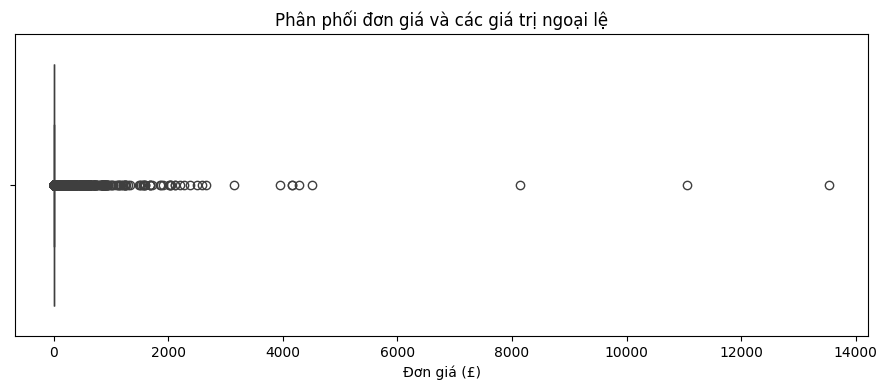

Các điểm ngoại lệ được giữ lại trong phân tích chính vì giá trị cao không tự động đồng nghĩa với lỗi dữ liệu.


In [9]:
# Phát hiện ngoại lệ đơn giá bằng quy tắc IQR
Q1 = df_clean["UnitPrice"].quantile(0.25)
Q3 = df_clean["UnitPrice"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean["UnitPrice"] < lower_bound)
    | (df_clean["UnitPrice"] > upper_bound)
)
outliers = df_clean.loc[outlier_mask]

print(f"Q1: £{Q1:.2f}")
print(f"Q3: £{Q3:.2f}")
print(f"IQR: £{IQR:.2f}")
print(f"Ngưỡng dưới: £{lower_bound:.2f}; ngưỡng trên: £{upper_bound:.2f}")
print(f"Số dòng có đơn giá ngoại lệ theo IQR: {len(outliers):,} ({len(outliers)/len(df_clean)*100:.2f}%)")

plt.figure(figsize=(9, 4))
sns.boxplot(x=df_clean["UnitPrice"])
plt.title("Phân phối đơn giá và các giá trị ngoại lệ")
plt.xlabel("Đơn giá (£)")
plt.tight_layout()
plt.show()

print("Các điểm ngoại lệ được giữ lại trong phân tích chính vì giá trị cao không tự động đồng nghĩa với lỗi dữ liệu.")

**PHẦN 4. PHÂN TÍCH HIỆU QUẢ BÁN HÀNG THEO SẢN PHẨM**
- Thống kê mô tả Quantity, UnitPrice và Revenue.
- Tổng hợp Doanh thu và Số lượng bán theo StockCode.
- Xếp hạng Top 10 sản phẩm theo Doanh thu và Số lượng bán.
- So sánh hai nhóm để nhận diện Sản phẩm nổi bật.

In [10]:
# Thống kê mô tả Quantity, UnitPrice và Revenue
display(df_clean[["Quantity", "UnitPrice", "Revenue"]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Quantity,524878.0,10.62,156.28,1.0,1.00,4.00,11.00,80995.00
UnitPrice,524878.0,3.92,36.09,0.0,1.25,2.08,4.13,13541.33
Revenue,524878.0,20.28,271.69,0.0,3.90,9.92,17.70,168469.60


In [11]:
# Tổng hợp Doanh thu, Số lượng bán và Số hóa đơn theo StockCode
def first_nonempty_description(series):
    values = series.dropna().astype(str).str.strip()
    values = values[values.ne("")]
    if values.empty:
        return "Không có mô tả"
    return values.mode().iloc[0]

product_analysis = df_clean.groupby("StockCode").agg(
    ProductName=("Description", first_nonempty_description),
    TotalRevenue=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    InvoiceCount=("InvoiceNo", "nunique")
).reset_index()

product_analysis = product_analysis.sort_values(
    "TotalRevenue", ascending=False
).reset_index(drop=True)

display(product_analysis.head(10).style.format({
    "TotalRevenue": "£{:,.2f}", "TotalQuantity": "{:,.0f}",
    "InvoiceCount": "{:,.0f}"
}))

,StockCode,ProductName,TotalRevenue,TotalQuantity,InvoiceCount
0,DOT,DOTCOM POSTAGE,"£206,248.77",706,706
1,22423,REGENCY CAKESTAND 3 TIER,"£174,156.54","13,851","1,988"
2,23843,"PAPER CRAFT , LITTLE BIRDIE","£168,469.60","80,995",1
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"£104,462.75","37,641","2,198"
4,47566,PARTY BUNTING,"£99,445.23","18,283","1,685"
5,85099B,JUMBO BAG RED RETROSPOT,"£94,159.81","48,371","2,089"
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,"£81,700.92","78,033",247
7,POST,POSTAGE,"£78,101.88","3,150","1,126"
8,M,Manual,"£77,750.27","6,984",289
9,23084,RABBIT NIGHT LIGHT,"£66,870.03","30,739",994


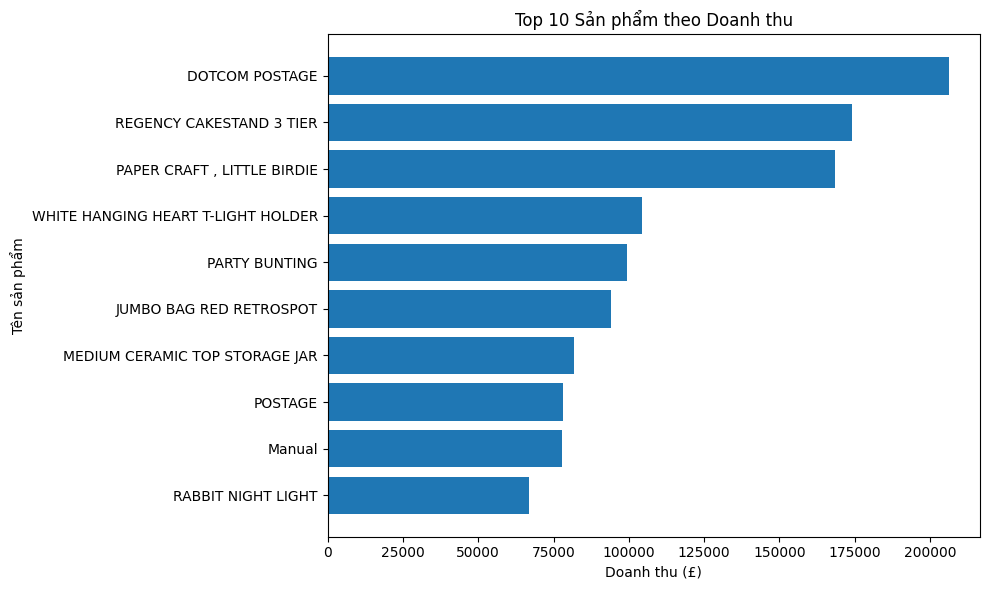

In [12]:
# Top 10 Sản phẩm dẫn đầu về Doanh thu
top_revenue = product_analysis.head(10).copy()
plot_revenue = top_revenue.sort_values(
    "TotalRevenue", ascending=True
)
plt.figure(figsize=(10, 6))
plt.barh(
    plot_revenue["ProductName"],
    plot_revenue["TotalRevenue"]
)
plt.title("Top 10 Sản phẩm theo Doanh thu")
plt.xlabel("Doanh thu (£)")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()

In [13]:
# Top 10 Sản phẩm dẫn đầu về Số lượng bán
top_quantity = product_analysis.sort_values(
    "TotalQuantity", ascending=False
).head(10).copy()

display(top_quantity.style.format({
    "TotalRevenue": "£{:,.2f}", "TotalQuantity": "{:,.0f}",
    "InvoiceCount": "{:,.0f}"
}))

,StockCode,ProductName,TotalRevenue,TotalQuantity,InvoiceCount
2,23843,"PAPER CRAFT , LITTLE BIRDIE","£168,469.60","80,995",1
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,"£81,700.92","78,033",247
14,22197,POPCORN HOLDER,"£51,334.47","56,898","1,392"
149,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"£13,814.01","54,951",535
5,85099B,JUMBO BAG RED RETROSPOT,"£94,159.81","48,371","2,089"
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"£104,462.75","37,641","2,198"
87,21212,PACK OF 72 RETROSPOT CAKE CASES,"£21,246.45","36,396","1,320"
11,84879,ASSORTED COLOUR BIRD ORNAMENT,"£58,927.62","36,362","1,455"
9,23084,RABBIT NIGHT LIGHT,"£66,870.03","30,739",994
117,22492,MINI PAINT SET VINTAGE,"£16,937.82","26,633",380


In [14]:
# So sánh nhóm Top 10 Doanh thu với Top 10 Số lượng bán
revenue_codes = set(top_revenue["StockCode"])
quantity_codes = set(top_quantity["StockCode"])
common_codes = revenue_codes & quantity_codes

print(f"Số mã xuất hiện trong cả hai nhóm Top 10: {len(common_codes)}")
print("Các mã cùng xuất hiện:", ", ".join(sorted(common_codes)) if common_codes else "Không có")

comparison = product_analysis[
    product_analysis["StockCode"].isin(revenue_codes | quantity_codes)
].copy()
comparison["Nhom"] = comparison["StockCode"].apply(
    lambda x: "Cả hai nhóm" if x in common_codes
    else ("Top doanh thu" if x in revenue_codes else "Top số lượng")
)
display(comparison.sort_values(["Nhom", "TotalRevenue"], ascending=[True, False])
        [["StockCode", "ProductName", "Nhom", "TotalRevenue", "TotalQuantity", "InvoiceCount"]])

Số mã xuất hiện trong cả hai nhóm Top 10: 5
Các mã cùng xuất hiện: 23084, 23166, 23843, 85099B, 85123A


,StockCode,ProductName,Nhom,TotalRevenue,TotalQuantity,InvoiceCount
2,23843,"PAPER CRAFT , LITTLE BIRDIE",Cả hai nhóm,168469.60,80995,1
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Cả hai nhóm,104462.75,37641,2198
5,85099B,JUMBO BAG RED RETROSPOT,Cả hai nhóm,94159.81,48371,2089
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,Cả hai nhóm,81700.92,78033,247
9,23084,RABBIT NIGHT LIGHT,Cả hai nhóm,66870.03,30739,994
0,DOT,DOTCOM POSTAGE,Top doanh thu,206248.77,706,706
1,22423,REGENCY CAKESTAND 3 TIER,Top doanh thu,174156.54,13851,1988
4,47566,PARTY BUNTING,Top doanh thu,99445.23,18283,1685
7,POST,POSTAGE,Top doanh thu,78101.88,3150,1126
8,M,Manual,Top doanh thu,77750.27,6984,289


**PHẦN 5. PHÂN TÍCH SỰ KHÁC BIỆT VỀ DOANH THU GIỮA CÁC QUỐC GIA**
- Tổng hợp Doanh thu, Số lượng bán và Số hóa đơn theo Quốc gia.
- Tính tỷ trọng đóng góp Doanh thu của từng Quốc gia.
- Xếp hạng và trực quan hóa các thị trường nổi bật.
- Phân tích riêng các thị trường ngoài United Kingdom.

In [15]:
# Tổng hợp Doanh thu, Số lượng bán, Số hóa đơn và Tỷ trọng theo Quốc gia
country_analysis = df_clean.groupby("Country").agg(
    TotalRevenue=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    InvoiceCount=("InvoiceNo", "nunique")
).reset_index()

country_analysis["RevenueShare_pct"] = (
    country_analysis["TotalRevenue"] / country_analysis["TotalRevenue"].sum() * 100
)
country_analysis = country_analysis.sort_values(
    "TotalRevenue", ascending=False
).reset_index(drop=True)

display(country_analysis.head(10).style.format({
    "TotalRevenue": "£{:,.2f}", "TotalQuantity": "{:,.0f}",
    "InvoiceCount": "{:,.0f}", "RevenueShare_pct": "{:.2f}%"
}))

,Country,TotalRevenue,TotalQuantity,InvoiceCount,RevenueShare_pct
0,United Kingdom,"£9,001,744.09","4,646,906","18,019",84.59%
1,Netherlands,"£285,446.34","200,361",94,2.68%
2,EIRE,"£283,140.52","147,007",288,2.66%
3,Germany,"£228,678.40","119,154",457,2.15%
4,France,"£209,625.37","112,060",392,1.97%
5,Australia,"£138,453.81","83,891",57,1.30%
6,Spain,"£61,558.56","27,933",90,0.58%
7,Switzerland,"£57,067.60","30,617",54,0.54%
8,Belgium,"£41,196.34","23,237",98,0.39%
9,Sweden,"£38,367.83","36,078",36,0.36%


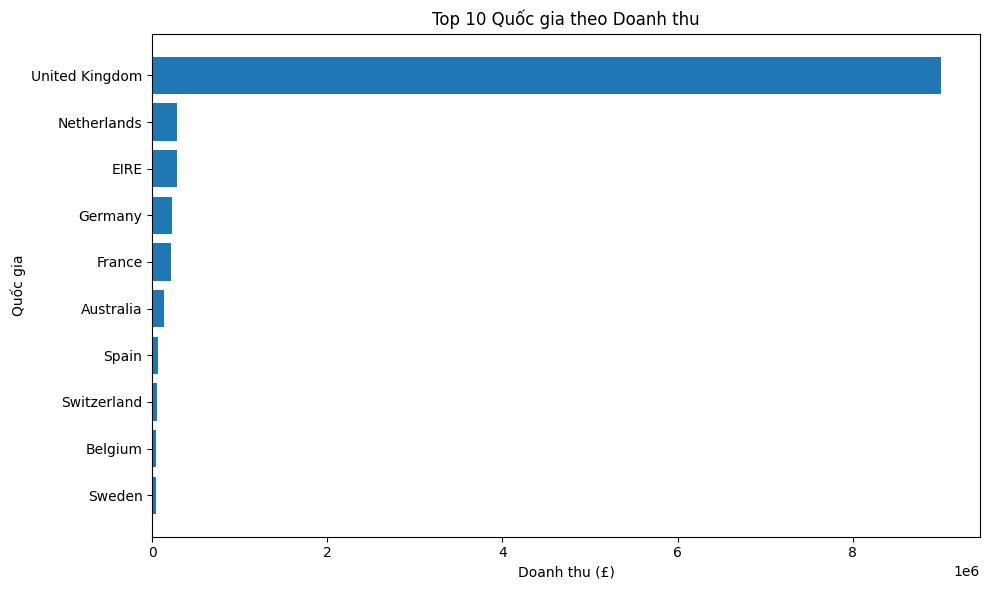

Tỷ trọng Doanh thu của 5 Quốc gia đứng đầu: 94.05%


In [16]:
# Top 10 Quốc gia dẫn đầu về Doanh thu
country_top10 = country_analysis.head(10).sort_values(
    "TotalRevenue", ascending=True
)
plt.figure(figsize=(10, 6))
plt.barh(
    country_top10["Country"],
    country_top10["TotalRevenue"]
)
plt.title("Top 10 Quốc gia theo Doanh thu")
plt.xlabel("Doanh thu (£)")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()
top5_share = country_analysis.head(5)["RevenueShare_pct"].sum()
print(f"Tỷ trọng Doanh thu của 5 Quốc gia đứng đầu: {top5_share:.2f}%")

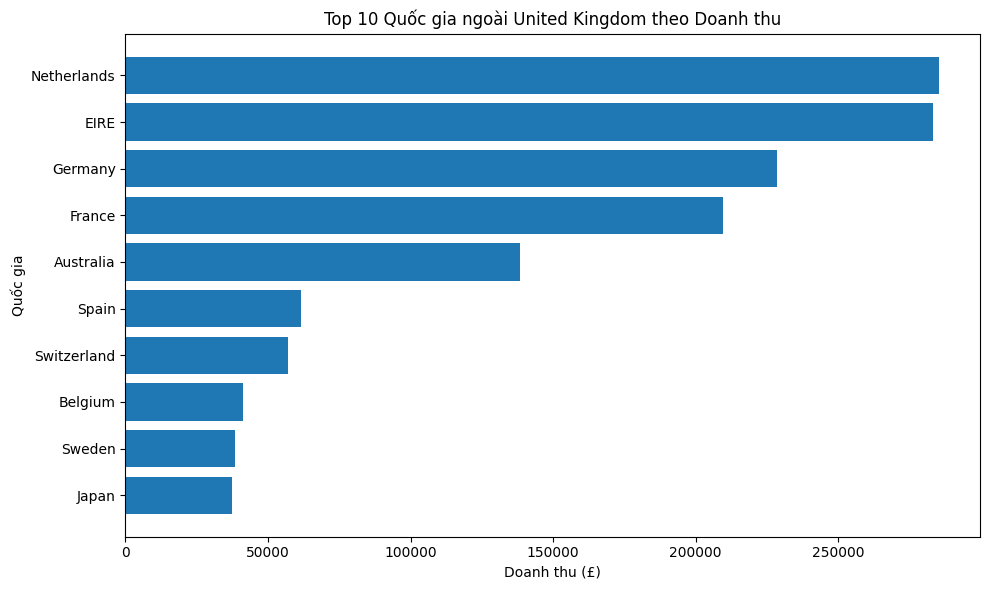

In [17]:
# Top 10 thị trường ngoài United Kingdom dẫn đầu về Doanh thu
non_uk = country_analysis[country_analysis["Country"] != "United Kingdom"].copy()
non_uk_top10 = non_uk.head(10).sort_values("TotalRevenue", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(non_uk_top10["Country"], non_uk_top10["TotalRevenue"])
plt.title("Top 10 Quốc gia ngoài United Kingdom theo Doanh thu")
plt.xlabel("Doanh thu (£)")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

**PHẦN 6. PHÂN TÍCH MỐI QUAN HỆ GIỮA CÁC BIẾN**

Phân tích mối tương quan Pearson giữa ba biến `Quantity`, `UnitPrice` và `Revenue` nhằm đánh giá mức độ và chiều hướng của mối liên hệ tuyến tính giữa các biến. Kết quả được trình bày thông qua ma trận tương quan (heatmap) và biểu đồ phân tán (scatter plot). Qua đó hỗ trợ nhận diện các xu hướng và đặc điểm nổi bật của dữ liệu giao dịch.

**Giới hạn diễn giải:** `Revenue` được tính trực tiếp bằng `Quantity × UnitPrice`, do đó mối liên hệ giữa doanh thu với hai biến thành phần có sự phụ thuộc về mặt toán học. Hệ số tương quan Pearson chỉ phản ánh mức độ liên hệ tuyến tính trong tập dữ liệu được giữ lại sau tiền xử lý, không đủ cơ sở để khẳng định quan hệ nhân quả. Ngoài ra, sự phân phối lệch và các giá trị ngoại lai có thể ảnh hưởng đến kết quả ước lượng hệ số tương quan.


In [18]:
# Ma trận tương quan Pearson giữa Quantity, UnitPrice và Revenue
corr = df_clean[["Quantity", "UnitPrice", "Revenue"]].corr(method="pearson")
display(corr.round(3))

,Quantity,UnitPrice,Revenue
Quantity,1.000,-0.004,0.907
UnitPrice,-0.004,1.000,0.137
Revenue,0.907,0.137,1.000


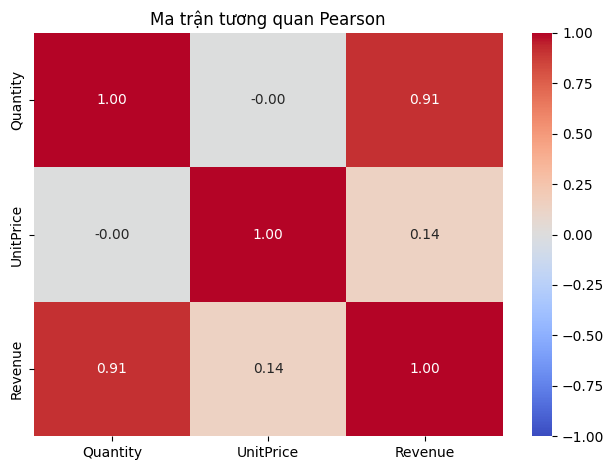

In [19]:
# Trực quan hóa ma trận tương quan Pearson
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)
plt.title("Ma trận tương quan Pearson")
plt.tight_layout()
plt.show()

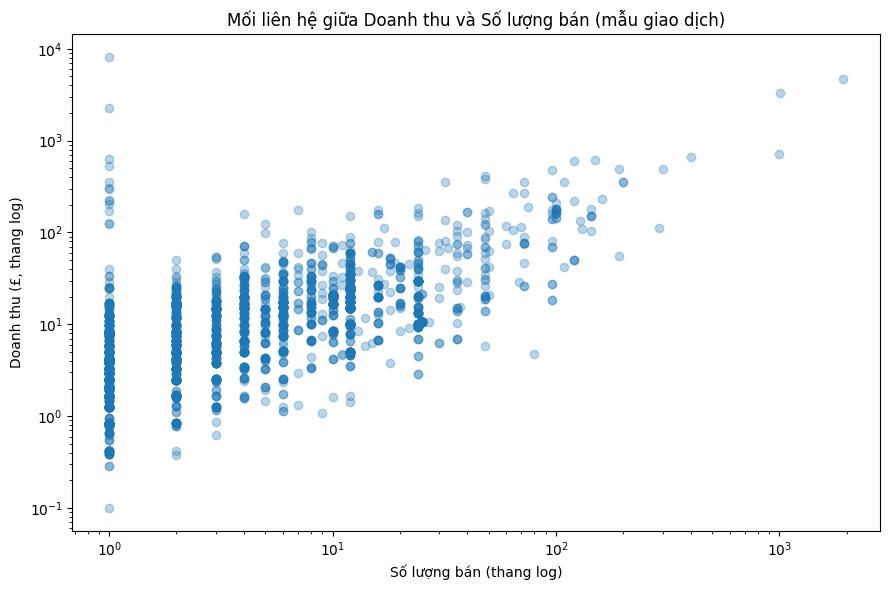

In [20]:
# Trực quan hóa Scatter plot thể hiện mối quan hệ giữa Doanh thu và Số lượng bán
sample_data = df_clean.sample(n=min(3000, len(df_clean)), random_state=42)

# Dùng các giá trị dương để biểu diễn trên thang log
plt.figure(figsize=(9, 6))
plt.scatter(sample_data["Quantity"], sample_data["Revenue"], alpha=0.3)
plt.xscale("log")
plt.yscale("log")
plt.title("Mối liên hệ giữa Doanh thu và Số lượng bán (mẫu giao dịch)")
plt.xlabel("Số lượng bán (thang log)")
plt.ylabel("Doanh thu (£, thang log)")
plt.tight_layout()
plt.show()

**PHẦN 7. TỔNG HỢP PHÁT HIỆN ĐỊNH LƯỢNG**
- Tổng hợp các kết quả nổi bật từ quá trình phân tích.
- Đối chiếu số liệu về Sản phẩm, Quốc gia và Tương quan.
- Làm cơ sở đề xuất các quyết định kinh doanh phù hợp.

In [21]:
# Tổng hợp các phát hiện định lượng từ kết quả thực tế
top_revenue_product = top_revenue.iloc[0]
top_quantity_product = top_quantity.iloc[0]
top_country = country_analysis.iloc[0]
retained_rate = len(df_clean) / len(df_raw) * 100
top_product_share = top_revenue_product["TotalRevenue"] / total_revenue * 100
top_country_share = top_country["RevenueShare_pct"]
quantity_revenue_corr = corr.loc["Quantity", "Revenue"]
unitprice_revenue_corr = corr.loc["UnitPrice", "Revenue"]
overlap_count = len(common_codes)

findings = pd.DataFrame([
    ["Tỷ lệ dòng được giữ lại", f"{retained_rate:.2f}%",
     "Phản ánh mức dữ liệu còn lại sau làm sạch.",
     "Lưu rõ quy tắc lọc và kiểm tra độ nhạy nếu thay đổi phạm vi giao dịch."],

    ["Sản phẩm có Doanh thu cao nhất",
     f'{top_revenue_product["StockCode"]} – {top_revenue_product["ProductName"]}: £{top_revenue_product["TotalRevenue"]:,.2f} ({top_product_share:.2f}% doanh thu)',
     "Cho biết mã sản phẩm đóng góp Doanh thu lớn nhất trong tập giao dịch được giữ lại.",
     "Ưu tiên theo dõi khả năng cung ứng và biến động Doanh thu của Sản phẩm này."],

    ["Sản phẩm bán nhiều nhất",
     f'{top_quantity_product["StockCode"]} – {top_quantity_product["ProductName"]}: {top_quantity_product["TotalQuantity"]:,.0f} đơn vị',
     "Sản phẩm bán nhiều nhất không nhất thiết tạo Doanh thu cao nhất.",
     "Kết hợp Số lượng bán và Doanh thu khi lập kế hoạch tồn kho, không chỉ dựa vào số lượng."],

    ["Quốc gia có Doanh thu cao nhất",
     f'{top_country["Country"]}: £{top_country["TotalRevenue"]:,.2f} ({top_country_share:.2f}% doanh thu)',
     "Xác định thị trường đóng góp Doanh thu lớn nhất trong dữ liệu.",
     "Ưu tiên theo dõi nhu cầu và khả năng phục vụ tại thị trường này."],

    ["Tỷ trọng Top 5 quốc gia", f"{top5_share:.2f}%",
     "Đo mức độ tập trung Doanh thu ở nhóm thị trường dẫn đầu.",
     "Theo dõi rủi ro phụ thuộc thị trường và đánh giá cơ hội mở rộng thị trường khác."],

    ["Mức giao nhau giữa hai Top 10", f"{overlap_count}/10 mã",
     "Cho biết có bao nhiêu mã vừa thuộc nhóm Doanh thu cao vừa thuộc nhóm Số lượng cao.",
     "Phân loại riêng Sản phẩm Doanh thu cao và Sản phẩm bán chạy để hỗ trợ quyết định Danh mục."],

    ["Tương quan Quantity-Revenue", f"Pearson r = {quantity_revenue_corr:.3f}",
     "Mô tả liên hệ tuyến tính, Doanh thu được tính từ Quantity và UnitPrice nên cần thận trọng khi diễn giải.",
     "Không xem tương quan là quan hệ nhân quả, kết hợp phân tích theo Sản phẩm và Thị trường."],

    ["Tương quan UnitPrice-Revenue", f"Pearson r = {unitprice_revenue_corr:.3f}",
     "Hệ số có thể chịu ảnh hưởng bởi phân phối lệch, ngoại lệ và cấu trúc công thức Doanh thu.",
     "Đọc cùng thống kê mô tả và biểu đồ phân tán, không suy luận nhân quả."]
], columns=["Phát hiện", "Kết quả thực tế", "Ý nghĩa", "Hàm ý quản trị"])

display(findings.style
    .set_properties(**{
        "white-space": "normal",
        "text-align": "left",
        "vertical-align": "top"
    })
    .set_table_styles([
        {"selector": "th", "props": [
            ("text-align", "center"),
            ("vertical-align", "middle")
        ]}
    ])
)

,Phát hiện,Kết quả thực tế,Ý nghĩa,Hàm ý quản trị
0,Tỷ lệ dòng được giữ lại,96.86%,Phản ánh mức dữ liệu còn lại sau làm sạch.,Lưu rõ quy tắc lọc và kiểm tra độ nhạy nếu thay đổi phạm vi giao dịch.
1,Sản phẩm có Doanh thu cao nhất,"DOT – DOTCOM POSTAGE: £206,248.77 (1.94% doanh thu)",Cho biết mã sản phẩm đóng góp Doanh thu lớn nhất trong tập giao dịch được giữ lại.,Ưu tiên theo dõi khả năng cung ứng và biến động Doanh thu của Sản phẩm này.
2,Sản phẩm bán nhiều nhất,"23843 – PAPER CRAFT , LITTLE BIRDIE: 80,995 đơn vị",Sản phẩm bán nhiều nhất không nhất thiết tạo Doanh thu cao nhất.,"Kết hợp Số lượng bán và Doanh thu khi lập kế hoạch tồn kho, không chỉ dựa vào số lượng."
3,Quốc gia có Doanh thu cao nhất,"United Kingdom: £9,001,744.09 (84.59% doanh thu)",Xác định thị trường đóng góp Doanh thu lớn nhất trong dữ liệu.,Ưu tiên theo dõi nhu cầu và khả năng phục vụ tại thị trường này.
4,Tỷ trọng Top 5 quốc gia,94.05%,Đo mức độ tập trung Doanh thu ở nhóm thị trường dẫn đầu.,Theo dõi rủi ro phụ thuộc thị trường và đánh giá cơ hội mở rộng thị trường khác.
5,Mức giao nhau giữa hai Top 10,5/10 mã,Cho biết có bao nhiêu mã vừa thuộc nhóm Doanh thu cao vừa thuộc nhóm Số lượng cao.,Phân loại riêng Sản phẩm Doanh thu cao và Sản phẩm bán chạy để hỗ trợ quyết định Danh mục.
6,Tương quan Quantity-Revenue,Pearson r = 0.907,"Mô tả liên hệ tuyến tính, Doanh thu được tính từ Quantity và UnitPrice nên cần thận trọng khi diễn giải.","Không xem tương quan là quan hệ nhân quả, kết hợp phân tích theo Sản phẩm và Thị trường."
7,Tương quan UnitPrice-Revenue,Pearson r = 0.137,"Hệ số có thể chịu ảnh hưởng bởi phân phối lệch, ngoại lệ và cấu trúc công thức Doanh thu.","Đọc cùng thống kê mô tả và biểu đồ phân tán, không suy luận nhân quả."


**PHẦN 8. KẾT LUẬN, ĐỀ XUẤT VÀ HẠN CHẾ**

Dựa trên kết quả phân tích bộ dữ liệu **Online Retail** sau khi làm sạch, nghiên cứu xác định các Sản phẩm và Quốc gia dẫn đầu về Doanh thu, đánh giá được mức độ tập trung Doanh thu theo Thị trường. Việc so sánh Doanh thu với Số lượng bán cho thấy hai chỉ tiêu có thể phản ánh những khía cạnh khác nhau của hoạt động kinh doanh. Các hệ số tương quan Pearson cung cấp thông tin về mối liên hệ tuyến tính giữa `Quantity`, `UnitPrice` và `Revenue` nhưng không chứng minh quan hệ nhân quả.

**Đề xuất quản trị:**
- Quản trị sản phẩm: Ưu tiên theo dõi khả năng cung ứng của sản phẩm đóng góp doanh thu cao; kết hợp doanh thu, số lượng bán và số hóa đơn khi lập kế hoạch danh mục.

- Quản trị thị trường: Theo dõi tỷ trọng doanh thu của các quốc gia dẫn đầu để đánh giá mức độ tập trung và cân nhắc mở rộng thị trường dựa trên dữ liệu bổ sung.

- Ra quyết định: Kết hợp kết quả phân tích với thông tin chi phí và vận hành để nâng cao tính chính xác của các quyết định quản trị.

**Hạn chế:** Kết quả phụ thuộc vào quy tắc làm sạch dữ liệu, đặc biệt là việc loại bỏ giao dịch hủy và các bản ghi có số lượng hoặc đơn giá không dương. Do dữ liệu chưa cung cấp đầy đủ thông tin chi phí, nghiên cứu chưa thể kết luận về lợi nhuận. Ngoài ra, tương quan không đồng nghĩa với quan hệ nhân quả. Vì vậy, cần kiểm tra lại toàn bộ notebook trên dữ liệu gốc và đối chiếu các kết quả định lượng trước khi đưa ra kết luận cuối cùng.


In [22]:
# Xuất bảng kết quả ra Excel để phục vụ báo cáo
output_file = "Ket_qua_De_tai_3.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    cleaning_summary.to_excel(writer, sheet_name="Lam_sach", index=False)
    kpi_overview.to_excel(writer, sheet_name="Tong_quan", index=False)
    product_analysis.to_excel(writer, sheet_name="San_pham", index=False)
    top_revenue.to_excel(writer, sheet_name="Top_doanh_thu", index=False)
    top_quantity.to_excel(writer, sheet_name="Top_so_luong", index=False)
    country_analysis.to_excel(writer, sheet_name="Quoc_gia", index=False)
    corr.to_excel(writer, sheet_name="Tuong_quan")
    findings.to_excel(writer, sheet_name="Phat_hien", index=False)

    for ws in writer.sheets.values():
        for col in ws.columns:
            max_length = max(
                len(str(cell.value)) if cell.value is not None else 0
                for cell in col
            )
            ws.column_dimensions[col[0].column_letter].width = min(
                max_length + 2, 100
            )

print(f"Đã xuất kết quả: {output_file}")
from google.colab import files
files.download(output_file)

Đã xuất kết quả: Ket_qua_De_tai_3.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>